# Tax-loss harvesting: what it does, what it costs, what it cannot do

*Not tax advice. The tax model is simplified; the reading guide at the end lists what it leaves out. The notebook runs offline in about 30 seconds and writes no files.*

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab, Config, Market, ScreenBuilder, ExitPolicy, ExitScreen
from screenlab.backtest import run
from screenlab.data import add_ratios
from screenlab.harvesting import TaxLossHarvest
from screenlab.taxes import CanadianTax, PlaceholderCanadianTax, TaxConfig, assess
from screenlab.research.montecarlo_sp500 import INK, INK2, SURFACE, GRID, _style
from screenlab.research import tax_plots as tp

BLUE, ORANGE, GREEN, GREY, RED, PURPLE = "#0072B2", "#E69F00", "#009E73", "#6B6B6B", "#D55E00", "#CC79A7"
HELD_COL = {"A": BLUE, "B": ORANGE, "C": GREEN, "cash": "#c9c8c2"}
OFF_COL, ON_COL = BLUE, RED                       # harvesting off / on, in every chart of section 2 and 3
BH_INDEX = "Buy and hold the index (after tax)"
plt.rcParams["figure.dpi"] = 80
_style()
usd = lambda v: f"-${-v:,.0f}" if round(v) < 0 else f"${v:,.0f}"
pc = lambda v, d=2: f"{100 * v:.{d}f}%"
pts = lambda v, d=2: f"{100 * v:+.{d}f}"
md = lambda text: display(Markdown(text.replace("$", r"\$")))      # a bare $ pair would be read as maths
mdates_num = mdates.date2num

# ---- tiny hand-built markets (the same builders as tests/test_harvesting.py) ---------------------------------------
CAP = 100_000.0
FLAT_TAX = PlaceholderCanadianTax(marginal_rate=0.40, federal_dtc=0.15, provincial_dtc=0.10, provincial_dtc_noneligible=0.03)
DATES = pd.bdate_range("2020-01-01", "2022-12-31")
END = DATES[-1]

def step(*pairs):
    "A price path that is 1.0 until the first date, then jumps to each level from its date on."
    s = pd.Series(1.0, index=DATES)
    for d, v in pairs:
        s[s.index >= d] = v
    return s

def toy_market(prices, caps):
    "`caps` {rebalance date: {name: market cap}} decides which names the 'top n by market cap' screen wants."
    rows = [dict(date=pd.Timestamp(d), ticker=t, sector="x", price=10.0, market_cap=c, dividend=0.0)
            for d, cs in caps.items() for t, c in cs.items()]
    return Market(add_ratios(pd.DataFrame(rows)), pd.DataFrame(prices))

def toy_screen(n):
    return ScreenBuilder("top", n=n).rank(market_cap="desc").build()

def toy_run(mkt, n, harvest, start="2020-01-01", exit=None, **cfg):
    tax = TaxConfig(model=FLAT_TAX, capital=CAP, pay_from_portfolio=False, harvest=harvest)
    c = Config(rebalance_months=12, cost_bps=0, min_holdings=1, tax=tax, exit=exit, **cfg)
    return run(toy_screen(n), mkt, c, start=start)

def held_segments(res, name, end=END, reentry=None, start=pd.Timestamp("2020-01-01")):
    "[(what is held, from, to)] around the first loss sale of `name`; cash until `reentry` (default: the sale day)."
    h = res.harvest.iloc[0]
    sale = h["date"]
    back = h["rebought"] if pd.notna(h["rebought"]) else end
    reentry = sale if reentry is None else reentry
    seg = [(name, start, sale)]
    if isinstance(h["replacement_name"], str):                 # a second pick: cash until re-entry, then the pick
        seg += [("cash", sale, reentry), (h["replacement_name"], reentry, back)]
    else:                                                       # no pick: cash until the name is bought again
        seg.append(("cash", sale, back))
    seg.append((name, back, end))
    return [s for s in seg if s[2] > s[1]]

def draw_held(ax, segs, label, window=None, denied_at=None):
    "One horizontal strip: what the account holds, when."
    for what, a, b in segs:
        ax.barh(0, (b - a).days, left=mdates_num(a), height=0.62, color=HELD_COL[what], edgecolor=SURFACE, lw=1.5)
        if (b - a).days > 45:
            ax.text(mdates_num(a) + (b - a).days / 2, 0, what, ha="center", va="center",
                    fontsize=9.5, color=INK if what in ("cash", "B") else "white", fontweight="bold")
    if window:
        ax.axvspan(mdates_num(window[0]), mdates_num(window[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
    if denied_at is not None:
        ax.plot([mdates_num(denied_at)], [0.5], marker="X", ms=11, color=RED, mec=SURFACE, clip_on=False, zorder=5)
    ax.set_yticks([]); ax.set_ylim(-0.5, 0.65); ax.grid(False)
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10, color=INK)
    for s in ("left", "top", "right"):
        ax.spines[s].set_visible(False)

def strip_legend(fig, sale_label, sale_marker, sale_color, extra=()):
    "One legend under a figure of strips: what each colour of the strips is, the 30-day window, the sale and the denied loss."
    handles = [Patch(color=HELD_COL["A"], label="holds A"), Patch(color=HELD_COL["B"], label="holds B (the second pick)"),
               Patch(color=HELD_COL["cash"], label="holds cash"),
               Patch(color=ORANGE, alpha=0.20, label="30 days after the sale: buying A here denies the loss"),
               Line2D([], [], marker=sale_marker, color=sale_color, lw=0, ms=8, label=sale_label),
               Line2D([], [], marker="X", color=RED, lw=0, ms=9, label="loss denied by the rebuy"), *extra]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False)

# ---- section 1: one name, one loss -----------------------------------------------------------------------------------
A = step(("2020-07-01", 0.8))            # A falls 20% on 1 July 2020 and stays there
FLAT = step()                            # B and C do not move
caps = {d: dict(A=3, B=2, C=1) for d in ("2020-01-01", "2021-01-01", "2022-01-03")}   # the screen always wants A
mk1 = toy_market(dict(A=A, B=FLAT, C=FLAT), caps)

VARIANTS = {"Second pick": TaxLossHarvest(replacement="second_pick"),
            "Stay out": TaxLossHarvest(replacement="stay_out"),
            "Allow denial": TaxLossHarvest(on_repick="allow_denial")}
VAR_COL = {"Second pick": PURPLE, "Stay out": GREEN, "Allow denial": RED}
none1 = toy_run(mk1, 1, None)                         # buy and hold A: the screen holds A every year, nothing is ever sold
res1 = {k: toy_run(mk1, 1, h) for k, h in VARIANTS.items()}
SALE1 = res1["Second pick"].harvest.iloc[0]["date"]
BH_A = "Buy and hold A (never sell)"

rows = {BH_A: dict(sold="never", back="-", meanwhile="-", value=none1.curve.iloc[-1] * CAP, realized=0.0, denied=0.0, acb=CAP)}
for k, r in res1.items():
    h = r.harvest.iloc[0]
    segs = held_segments(r, "A")
    rows[k] = dict(sold=h["date"].date(), back=h["rebought"].date(),
                   meanwhile=" then ".join(w for w, a, b in segs[1:-1] if w != "cash") or "cash",
                   value=r.curve.iloc[-1] * CAP, realized=abs(r.tax.loc[2020, "realized_losses"]), denied=h["denied"] * CAP,
                   acb=r.curve.loc[h["rebought"]] * CAP + h["acb_added"] * CAP)
t1 = pd.DataFrame(rows).T[["sold", "back", "meanwhile", "value", "realized", "denied", "acb"]].fillna("-")
t1.columns = ["A sold on", "A held again on", "held meanwhile", "account value at the end of 2022", "loss realized in 2020", "loss denied",
              "ACB of A afterwards"]
for c in ("account value at the end of 2022", "loss realized in 2020", "loss denied", "ACB of A afterwards"):
    t1[c] = t1[c].map(usd)
FLAT_RATE = 0.20
LOSS1 = float(rows["Second pick"]["realized"])
days_out1 = {k: (res1[k].harvest.iloc[0]["rebought"] - SALE1).days for k in res1}
same_value1 = all(np.allclose(r.curve.to_numpy(), none1.curve.to_numpy()) for r in res1.values())

# ---- section 2: harvesting on and off, on a Globe screen -------------------------------------------------------------
lab = Lab.synthetic(freq="ME", n_stocks=150, years=12, seed=3)
SCREEN = "dogs"
TAXC = dict(model=CanadianTax("AB", other_income=90_000), capital=100_000, account="taxable")
H_ON = TaxLossHarvest(threshold_pct=0.10, when="year_end", replacement="second_pick")
rep_off = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(**TAXC))
rep_on = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(harvest=H_ON, **TAXC))
off, on = rep_off.results[SCREEN], rep_on.results[SCREEN]
idx = tp.index_result(rep_on)                         # buy and hold the passive index in the same account, taxed the same way
BL = rep_on.benchmark_label
YEARS = (off.curve.index[-1] - off.curve.index[0]).days / 365.25

cols = ["CAGR", "AfterTaxCAGR", "TaxDrag/yr"]
tab2 = pd.DataFrame({"Buy and hold the index": rep_on.table.loc[BL], "Harvesting off": rep_off.table.loc[SCREEN],
                     "Harvesting on": rep_on.table.loc[SCREEN]}).T.reindex(columns=cols)
tab2["Traded a year"] = [np.nan, off.turnover.sum() / YEARS, on.turnover.sum() / YEARS]
tab2["Trading cost a year"] = [np.nan, off.costs.sum() / YEARS, on.costs.sum() / YEARS]
tab2["Tax paid over the run"] = [idx.tax["cum_tax_paid"].iloc[-1], off.tax["cum_tax_paid"].iloc[-1], on.tax["cum_tax_paid"].iloc[-1]]
tab2["Value of $100,000 after tax"] = [idx.after_tax_curve.iloc[-1] * CAP, off.after_tax_curve.iloc[-1] * CAP, on.after_tax_curve.iloc[-1] * CAP]
tab2["Harvested/yr"] = [np.nan, np.nan, rep_on.table.loc[SCREEN, "Harvested/yr"]]
tab2["TaxDeferred/yr"] = [np.nan, np.nan, rep_on.table.loc[SCREEN, "TaxDeferred/yr"]]
FMT2 = {"CAGR": "{:.2%}", "AfterTaxCAGR": "{:.2%}", "TaxDrag/yr": "{:.2%}", "Traded a year": "{:.0%}", "Trading cost a year": "{:.2%}",
        "Tax paid over the run": usd, "Value of $100,000 after tax": usd, "Harvested/yr": "{:.2%}", "TaxDeferred/yr": "{:.2%}"}

d = lambda c: rep_on.table.loc[SCREEN, c] - rep_off.table.loc[SCREEN, c]
d_pre, d_drag, d_at = d("CAGR"), -d("TaxDrag/yr"), d("AfterTaxCAGR")
tax_off, tax_on = off.tax["cum_tax_paid"].iloc[-1], on.tax["cum_tax_paid"].iloc[-1]
tax_idx = idx.tax["cum_tax_paid"].iloc[-1]
at_off, at_on, at_idx = (x.after_tax_curve.iloc[-1] * CAP for x in (off, on, idx))
pre_off, pre_on = off.curve.iloc[-1] * CAP, on.curve.iloc[-1] * CAP
gain_at, gain_pre = at_on - at_off, pre_on - pre_off
gain_tax = gain_at - gain_pre
gap_off, gap_on = at_idx - at_off, at_idx - at_on
turn_off, turn_on = off.turnover.sum() / YEARS, on.turnover.sum() / YEARS
cost_off, cost_on = off.costs.sum() / YEARS, on.costs.sum() / YEARS
hv = on.harvest
hsales = hv[hv["source"] == "harvest"]
n_h, n_sales, n_denied = len(hsales), len(hv), int((hv["denied"] > 0).sum())
name_days = int(hsales["days_out"].sum())
avg_n = float(rep_on.table.loc[SCREEN, "AvgN"])
share_out = name_days / (avg_n * (on.curve.index[-1] - on.curve.index[0]).days)
loss_sold, loss_denied = hv["loss"].sum() * CAP, hv["denied"].sum() * CAP
refund_on, refund_off = on.tax["refund"].sum(), off.tax["refund"].sum()
refund_years_on = [int(y) for y in on.tax.index[on.tax["refund"] > 0]]
refund_years_off = [int(y) for y in off.tax.index[off.tax["refund"] > 0]]
idx_at_cagr, off_at_cagr, on_at_cagr = (rep_on.table.loc[BL, "AfterTaxCAGR"], rep_off.table.loc[SCREEN, "AfterTaxCAGR"],
                                        rep_on.table.loc[SCREEN, "AfterTaxCAGR"])

n_lower, n_years = int((on.tax["tax_paid"] < off.tax["tax_paid"]).sum()), len(on.tax)
big_y = int((-on.tax["realized_losses"]).idxmax())            # the year with the largest realized losses, harvesting on

tax_diff = off.tax["tax_paid"] - on.tax["tax_paid"]           # positive: harvesting on paid less that year
n_less, n_more = int((tax_diff > 0).sum()), int((tax_diff < 0).sum())
y_best, y_worst = int(tax_diff.idxmax()), int(tax_diff.idxmin())
same_y = int(tax_diff[on.tax["refund"] == 0].idxmax())       # the largest saving in a year with no refund: losses used in the year they arose

# the nine settings
WHEN = ["year_end", "rebalance", "both"]; THR = [0.05, 0.10, 0.20]
curves, srows = {}, []
for when in WHEN:
    for th in THR:
        h_ = TaxLossHarvest(threshold_pct=th, when=when, replacement="second_pick", report_deferral=False)
        r = lab.backtest([SCREEN], rebalance_months=12, tax=TaxConfig(harvest=h_, **TAXC)).results[SCREEN]
        curves[when, th] = (r.after_tax_curve - off.after_tax_curve) * CAP
        srows.append(dict(when=when, threshold=th, final=r.after_tax_curve.iloc[-1] * CAP,
                          gain=(r.after_tax_curve.iloc[-1] - off.after_tax_curve.iloc[-1]) * CAP,
                          harvests=int((r.harvest["source"] == "harvest").sum()) if r.harvest is not None else 0))
sens = pd.DataFrame(srows)
idx_gain_vs_off = at_idx - at_off
n_pos, n_neg = int((sens["gain"] > 0).sum()), int((sens["gain"] < 0).sum())
best, worst = sens.loc[sens["gain"].idxmax()], sens.loc[sens["gain"].idxmin()]
hv_by_thr = sens.groupby("threshold")["harvests"].agg(["min", "max"])

# ---- section 3: carry-back -------------------------------------------------------------------------------------------
def carry_events(years):
    ix = pd.date_range("2018-01-01", "2023-12-31", freq="D")
    ev = pd.DataFrame(0.0, index=ix, columns=["div_ca", "div_fx", "gain", "loss"])
    for y, (g, l) in years.items():
        ev.loc[f"{y}-06-01", ["gain", "loss"]] = [g, l]
    return pd.Series(1.0, index=ix), ev

def carry_case(years):
    curve, ev = carry_events(years)
    t, _ = assess(curve, ev, TaxConfig(model=FLAT_TAX, capital=CAP, pay_from_portfolio=False), CAP)
    return t

# gains are in units of the $100,000 start: 0.20 = $20,000
case1 = carry_case({2019: (0.20, 0), 2020: (0.30, 0), 2021: (0.40, 0), 2022: (0, -0.65)})
case2 = carry_case({2018: (0.10, 0), 2019: (0.20, 0), 2020: (0.30, 0), 2021: (0.40, 0), 2022: (0, -1.20)})

# ---- section 4: exits ------------------------------------------------------------------------------------------------
class Flag:
    "A risk flag set by hand: on for the calendar days from `start` to `end`."
    name = "flag"
    def __init__(self, start, end):
        self.start, self.end = pd.Timestamp(start), pd.Timestamp(end)
    def compute(self, mkt, macro=None):
        return pd.Series(((mkt.index >= self.start) & (mkt.index <= self.end)).astype(float), index=mkt.index)

S = pd.Timestamp("2020-09-01")
a_exit = step(("2020-07-01", 0.8), ("2020-09-20", 1.0), ("2020-10-05", 1.1))
mk4 = toy_market(dict(A=a_exit, B=FLAT, C=FLAT), caps)

def exit_run(back_on, harvest):
    pol = ExitPolicy(ExitScreen([Flag(S, back_on - pd.Timedelta(days=1))], threshold=0.5, lag=0), switch_cost_bps=0.0)
    return toy_run(mk4, 1, harvest, exit=pol)

EXITS = {"Back in at S+10, second pick": (S + pd.Timedelta(days=10), TaxLossHarvest(replacement="second_pick")),
         "Back in at S+31, second pick": (S + pd.Timedelta(days=31), TaxLossHarvest(replacement="second_pick")),
         "Back in at S+10, allow denial": (S + pd.Timedelta(days=10), TaxLossHarvest(on_repick="allow_denial"))}
EXIT_COL = dict(zip(EXITS, (PURPLE, GREEN, RED)))
res4 = {k: exit_run(b, h) for k, (b, h) in EXITS.items()}
BH_A4 = "Buy and hold A (no exit, never sell)"
CHK = pd.Timestamp("2020-10-06")
rows_4 = [{"variant": BH_A4, "sale recorded as": "-", "bought instead": "-", "A held again on": "-", "loss": "$0", "denied": "$0",
         "wealth on 6 Oct": usd(a_exit.loc[CHK] * CAP), "loss realized in 2020": "$0"}]
for k, r in res4.items():
    h = r.harvest.iloc[0]
    rows_4.append({"variant": k, "sale recorded as": h["source"], "loss": usd(h["loss"] * CAP),
                 "bought instead": h["replacement_name"] if isinstance(h["replacement_name"], str) else "A (the same name)",
                 "A held again on": h["rebought"].date(), "denied": usd(h["denied"] * CAP),
                 "wealth on 6 Oct": usd(r.curve.loc[CHK] * CAP), "loss realized in 2020": usd(abs(r.tax.loc[2020, "realized_losses"]))})
t4 = pd.DataFrame(rows_4).set_index("variant")[["sale recorded as", "loss", "bought instead", "A held again on", "denied", "loss realized in 2020", "wealth on 6 Oct"]]
w4 = {k: r.curve.loc[CHK] * CAP for k, r in res4.items()}
bh4 = a_exit.loc[CHK] * CAP

# ---- the summary at the top ------------------------------------------------------------------------------------------
WHEN_NAME = {"year_end": "at the year end only", "rebalance": "at the screen's rebalance only", "both": "at both"}
md(f"""## Summary

**What harvesting cost.** The test portfolio was the Globe and Mail "{SCREEN}" screen in a taxable Alberta account, $100,000 over {YEARS:.1f} years of synthetic Canadian data, rebalanced yearly. Harvesting made it trade {turn_on / turn_off:.1f} times as much: {pc(turn_off, 0)} of its value a year without harvesting and {pc(turn_on, 0)} with it, with trading cost rising from {pc(cost_off)} to {pc(cost_on)} of the portfolio a year. It made {n_h} year-end sales of names down more than 10%. Each sale was followed by a second pick held for 30 days and a swap back, so the account spent {name_days:,} name-days ({pc(share_out, 1)} of all its name-time) out of the names the screen had chosen. The superficial-loss rule denied part of the loss on {n_denied} of the {n_sales} loss sales ({usd(loss_denied)} of {usd(loss_sold)} of losses sold), because the screen wanted the name back inside the 30 days. Every one of those episodes was a sale, a purchase and a swap back that buy and hold never has.

**What it was worth.** Tax paid over the run fell from {usd(tax_off)} to {usd(tax_on)}, a saving of {usd(tax_off - tax_on)}. After-tax growth rose from {pc(off_at_cagr)} to {pc(on_at_cagr)} a year, which is {pts(d_at)} points: {pts(d_drag)} from lower tax drag and {pts(d_pre)} from a higher before-tax return, which came from the second picks doing better than the names they replaced (net of the extra trading cost) and was luck that could have gone the other way. In dollars, $100,000 became {usd(at_off)} without harvesting and {usd(at_on)} with it. That gain of {usd(gain_at)} was {usd(gain_pre)} before tax and the remaining {usd(gain_tax)} from tax, close to the {usd(tax_off - tax_on)} of tax saved. The carry-back refunded {usd(refund_on)} in {refund_years_on[0]} with harvesting on, against {usd(refund_off)} without it, so harvesting did not raise the refunds. The gain was positive in {n_pos} of nine threshold and timing settings and ranged from {usd(worst['gain'])} to {usd(best['gain'])}. Against buying and holding the passive index in the same account, which turned $100,000 into {usd(at_idx)} ({pc(idx_at_cagr)} a year after tax, with {usd(tax_idx)} of tax), harvesting closed {usd(gain_at)} of a {usd(gap_off)} shortfall and left the screen {usd(gap_on)} behind. The screen decided the result, and the tax technique moved it only a little.
""")

## Summary

**What harvesting cost.** The test portfolio was the Globe and Mail "dogs" screen in a taxable Alberta account, \$100,000 over 10.8 years of synthetic Canadian data, rebalanced yearly. Harvesting made it trade 1.9 times as much: 57% of its value a year without harvesting and 106% with it, with trading cost rising from 0.29% to 0.53% of the portfolio a year. It made 34 year-end sales of names down more than 10%. Each sale was followed by a second pick held for 30 days and a swap back, so the account spent 1,082 name-days (2.7% of all its name-time) out of the names the screen had chosen. The superficial-loss rule denied part of the loss on 4 of the 63 loss sales (\$5,957 of \$232,324 of losses sold), because the screen wanted the name back inside the 30 days. Every one of those episodes was a sale, a purchase and a swap back that buy and hold never has.

**What it was worth.** Tax paid over the run fell from \$21,419 to \$18,170, a saving of \$3,249. After-tax growth rose from 5.83% to 6.29% a year, which is +0.45 points: +0.17 from lower tax drag and +0.28 from a higher before-tax return, which came from the second picks doing better than the names they replaced (net of the extra trading cost) and was luck that could have gone the other way. In dollars, \$100,000 became \$184,817 without harvesting and \$193,582 with it. That gain of \$8,765 was \$5,782 before tax and the remaining \$2,982 from tax, close to the \$3,249 of tax saved. The carry-back refunded \$7,372 in 2009 with harvesting on, against \$14,100 without it, so harvesting did not raise the refunds. The gain was positive in 8 of nine threshold and timing settings and ranged from -\$8,077 to \$32,088. Against buying and holding the passive index in the same account, which turned \$100,000 into \$342,399 (12.03% a year after tax, with \$4,568 of tax), harvesting closed \$8,765 of a \$157,582 shortfall and left the screen \$148,817 behind. The screen decided the result, and the tax technique moved it only a little.


## How harvesting works

When a stock you own has fallen, selling it makes a **capital loss**. In a taxable account that loss cancels capital gains of this year, of the three years before, or of any later year, so it lowers your tax. **Harvesting** means selling a loser on purpose, near the end of the year, for that reason.

The Canadian **superficial-loss rule** limits it. If you, your spouse or a corporation you control buy the same stock within 30 days before or after the sale and still hold it at the end of that window, the loss is **denied**. A denied loss is not gone: it is added to the cost (the adjusted cost base, ACB) of the shares bought, so it comes back only when those shares are finally sold.

The library's harvesting stage sells losers, keeps the name on a **blocklist** for 30 days, and by default buys the screen's **second pick** meanwhile so the account stays invested. The notebook shows each part on small made-up markets where the arithmetic can be checked by eye (sections 1, 3 and 4), and the whole mechanism on a full screen (section 2). It uses one history and no Monte Carlo, so it measures the tax mechanics and not the chance of a good or bad market.

Every chart carries a grey dashed line, the base case. On the full screen it is buying and holding the passive index in the same account, taxed the same way. On the one-name markets it is buying and holding the same name and never selling, because that has the same exposure and involves no tax-driven trade. Each section opens with the question it answers, shows the evidence, and closes under "What the evidence says".

## 1. One name, one loss

This section asks what the superficial-loss rule does to a single loss, and what the three ways of spending the 30 days afterwards are worth. It comes first because one name and one loss can be checked by eye, before section 2 adds many names, gains and trading costs.

The market is made up. Stocks A, B and C move in steps so that the sums are exact. The screen is "hold the single biggest company", which is A, every year. A fell 20% on 1 July 2020 and stayed there. The account started with \$100,000 on 1 January 2020, and capital gains tax is a flat 20% of the gain, so a \$20,000 loss is worth \$4,000 of tax.

The base case is buying A and holding it without ever selling. That is the right comparison here because it has exactly the same exposure to A as every variant and involves no tax-driven trade, so any difference between a variant and the base case is caused by harvesting alone.

With harvesting on (threshold 10%), the stage sold A on the last trading day of 2020 and booked the loss. The screen wanted A again on 1 January 2021, a day later, which is the purchase the rule punishes. The three variants differ in what happens next. Under **second pick**, the default, A is blocked for 30 days, B (the next company down the screen's list) is held instead, and A is swapped back after the window. Under **stay out**, the proceeds wait in cash until the screen next wants A after the window. Under **allow denial**, A is bought straight back and the loss is denied.

In [2]:
display(t1)
print(f"flat tax rate 20%: a realized loss of {usd(LOSS1)} is worth {usd(LOSS1 * FLAT_RATE)} of tax in 2020.")

,A sold on,A held again on,held meanwhile,account value at the end of 2022,loss realized in 2020,loss denied,ACB of A afterwards
Buy and hold A (never sell),never,-,-,"$80,000",$0,$0,"$100,000"
Second pick,2020-12-31,2021-02-01,B,"$80,000","$20,000",$0,"$80,000"
Stay out,2020-12-31,2022-01-03,cash,"$80,000","$20,000",$0,"$80,000"
Allow denial,2020-12-31,2021-01-01,cash,"$80,000",$0,"$20,000","$100,000"


flat tax rate 20%: a realized loss of $20,000 is worth $4,000 of tax in 2020.


In [3]:
md(f"""
Second pick and stay out realized the full {usd(LOSS1)} loss in 2020, and the shares of A held afterwards cost only {usd(rows['Second pick']['acb'])}, so the loss was used and not merely postponed. Allow denial realized nothing in 2020. Its {usd(rows['Allow denial']['denied'])} was parked in the cost base of the shares bought back, which stood at {usd(rows['Allow denial']['acb'])} for a position worth {usd(rows['Allow denial']['value'])}, and it comes back only when those shares are sold. Buy and hold realized nothing and held the same position at the same {usd(CAP)} cost. The account was worth {usd(rows['Second pick']['value'])} at the end of 2022 in all four rows, so no variant changed what the account was worth. Each changed what the tax system owed.
""")


Second pick and stay out realized the full \$20,000 loss in 2020, and the shares of A held afterwards cost only \$80,000, so the loss was used and not merely postponed. Allow denial realized nothing in 2020. Its \$20,000 was parked in the cost base of the shares bought back, which stood at \$100,000 for a position worth \$80,000, and it comes back only when those shares are sold. Buy and hold realized nothing and held the same position at the same \$100,000 cost. The account was worth \$80,000 at the end of 2022 in all four rows, so no variant changed what the account was worth. Each changed what the tax system owed.


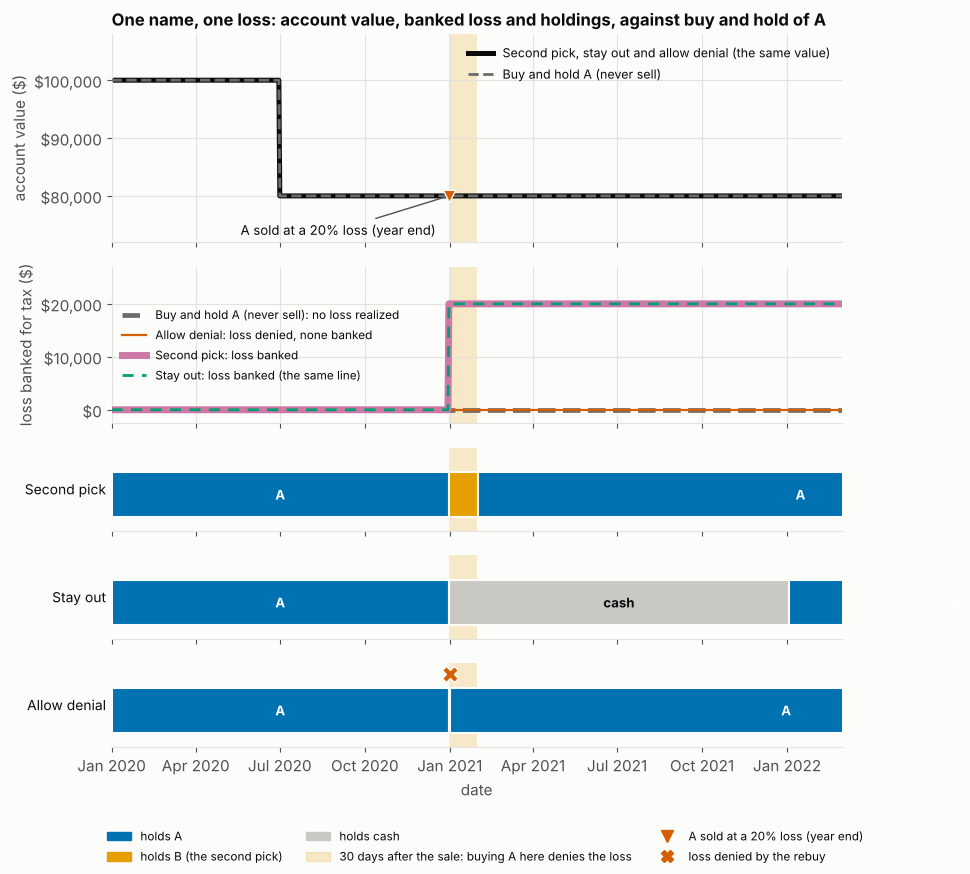

In [4]:
fig, axs = plt.subplots(5, 1, sharex=True, figsize=(10, 8.8), gridspec_kw=dict(height_ratios=[2.0, 1.5, 0.8, 0.8, 0.8], hspace=0.2))
win = (SALE1, SALE1 + pd.Timedelta(days=30))

def banked(r):
    "Realized losses waiting to be used against gains, from the tax table (known at each year end)."
    s = pd.Series(0.0, index=DATES)
    for y, v in r.tax["loss_carry_out"].items():
        s[s.index >= pd.Timestamp(f"{y}-12-31")] = max(float(v), 0.0)
    return s

ax = axs[0]
v = res1["Second pick"].curve * CAP
ax.plot(v.index, v.values, color=INK, lw=3.6, label="Second pick, stay out and allow denial (the same value)")
bh = none1.curve * CAP
ax.plot(bh.index, bh.values, color=tp.INDEX_COL, ls="--", lw=2.0, label=BH_A, zorder=4)
ax.scatter([SALE1], [v.loc[SALE1]], marker="v", s=80, color=RED, zorder=5, edgecolor=SURFACE)
ax.annotate("A sold at a 20% loss (year end)", (SALE1, v.loc[SALE1]), xytext=(-150, -28), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2))
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.set_ylim(72_000, 108_000); ax.set_ylabel("account value ($)")
ax.yaxis.set_major_formatter(lambda x, _: usd(x))
ax.legend(loc="upper right", fontsize=9)
ax.set_title("One name, one loss: account value, banked loss and holdings, against buy and hold of A", loc="left", fontsize=12, fontweight="bold")

ax = axs[1]
ax.plot(DATES, banked(none1).values, color=tp.INDEX_COL, ls="--", lw=3.4, label=BH_A + ": no loss realized", zorder=2)
ax.plot(DATES, banked(res1["Allow denial"]).values, color=VAR_COL["Allow denial"], lw=1.6, label="Allow denial: loss denied, none banked", zorder=3)
ax.plot(DATES, banked(res1["Second pick"]).values, color=VAR_COL["Second pick"], lw=5.0, label="Second pick: loss banked", zorder=3)
ax.plot(DATES, banked(res1["Stay out"]).values, color=VAR_COL["Stay out"], lw=2.0, ls=(0, (4, 3)), label="Stay out: loss banked (the same line)", zorder=4)
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.set_ylim(-2_500, 27_000); ax.set_ylabel("loss banked for tax ($)")
ax.yaxis.set_major_formatter(lambda x, _: usd(x))
ax.legend(loc="center left", fontsize=8.5)

for ax_, (name, r) in zip(axs[2:], res1.items()):
    h = r.harvest.iloc[0]
    draw_held(ax_, held_segments(r, "A"), name, window=win, denied_at=h["rebought"] if h["denied"] > 0 else None)
for ax_ in axs[:2]:
    ax_.set_facecolor(SURFACE)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axs[-1].set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-03-01"))
axs[-1].set_xlabel("date")
strip_legend(fig, "A sold at a 20% loss (year end)", "v", RED)
fig.subplots_adjust(left=0.17, bottom=0.14, top=0.95)
plt.show()

In [5]:
md(f"""
**What the evidence says.** Harvesting did not change the account's value in this market, which was {usd(rows['Second pick']['value'])} at the end of 2022 with or without it ({'identical on every day' if same_value1 else 'different on some days'}). It changed the tax position. Second pick and stay out banked a {usd(LOSS1)} loss, worth {usd(LOSS1 * FLAT_RATE)} of tax at 20% once there are gains to set it against, and the account paid nothing for that because A and B did not move while the account was away from A. Allow denial gave the benefit back, which makes a rebuy inside the window the one move that cancels the saving. Second pick and stay out tie here only because nothing moved: second pick was out of A for {days_out1['Second pick']} days and stay out for {days_out1['Stay out']}. On a path where A recovers, those days cost money, and section 4 shows how much.
""")


**What the evidence says.** Harvesting did not change the account's value in this market, which was \$80,000 at the end of 2022 with or without it (identical on every day). It changed the tax position. Second pick and stay out banked a \$20,000 loss, worth \$4,000 of tax at 20% once there are gains to set it against, and the account paid nothing for that because A and B did not move while the account was away from A. Allow denial gave the benefit back, which makes a rebuy inside the window the one move that cancels the saving. Second pick and stay out tie here only because nothing moved: second pick was out of A for 32 days and stay out for 368. On a path where A recovers, those days cost money, and section 4 shows how much.


## 2. With harvesting and without, on a real screen

Section 1 showed that one loss can be banked at no cost in wealth when nothing moves. This section asks what harvesting is worth on a screen that holds ten names, pays tax on gains and dividends, trades at a cost, and holds second picks while prices move. It follows from section 1 because the mechanics are the same. What is new is that the second picks, the trading costs and the gains the losses are set against are now real quantities and not zero.

The screen is the Globe and Mail **dogs** screen (the lowest-priced, high-yield names) over 12 years of the synthetic Canadian market, in a taxable account in Alberta with \$90,000 of other income, rebalanced once a year. With harvesting on, the stage sold any loser down more than 10% at each year end and held the second pick for 30 days. The market is made up so that the notebook runs offline, so the numbers show the machinery and are not a forecast.

The base case is buying and holding the passive index in the same account, taxed the same way: dividends taxed as received, and gains taxed only if the index is sold. It answers the question an investor faces first, which is whether to run the screen at all, and it is the grey dashed line in every chart. The comparison that isolates the tax technique is harvesting on against harvesting off, the same portfolio without the year-end sales, and both appear in every chart as well.

### 2.1 Growth and tax

The first question is whether harvesting raised after-tax growth, and by how much against both comparisons.

In [6]:
print("harvesting:", H_ON.describe())
display(tab2.style.format(FMT2, na_rep="-"))
print(f"change in growth a year, in percentage points: before tax {pts(d_pre)}, less tax drag {pts(d_drag)}, after tax {pts(d_at)}")
print(f"tax paid over the run: {usd(tax_off)} off, {usd(tax_on)} on, {usd(tax_idx)} for buy and hold of the index;"
      f" after-tax value of $100,000: {usd(at_off)} off, {usd(at_on)} on, {usd(at_idx)} for buy and hold of the index")

harvesting: on (threshold 10%, second pick, 30-day window)


,CAGR,AfterTaxCAGR,TaxDrag/yr,Traded a year,Trading cost a year,Tax paid over the run,"Value of $100,000 after tax",Harvested/yr,TaxDeferred/yr
Buy and hold the index,12.22%,12.03%,0.20%,-,-,"$4,568","$342,399",-,-
Harvesting off,6.69%,5.83%,0.86%,57%,0.29%,"$21,419","$184,817",-,-
Harvesting on,6.97%,6.29%,0.68%,106%,0.53%,"$18,170","$193,582",10.47%,0.30%


change in growth a year, in percentage points: before tax +0.28, less tax drag +0.17, after tax +0.45
tax paid over the run: $21,419 off, $18,170 on, $4,568 for buy and hold of the index; after-tax value of $100,000: $184,817 off, $193,582 on, $342,399 for buy and hold of the index


In [7]:
md(f"""
The table has one row for each portfolio. **Traded a year** is the one-way share of the portfolio sold and bought in a year, and **Trading cost a year** is what that cost. **Harvested/yr** is the average loss sold each year as a share of wealth. **TaxDeferred/yr** is the tax that loss postponed, found by re-running the same portfolio without harvesting. It is a deferral: a harvested loss lowers the cost of what is held afterwards, so the saving is partly a loan from the tax authority, repaid when the gain is realized. **TaxDeferred/yr should be ignored in a TFSA or RRSP**, where there is nothing to defer.

The before-tax return also changed, because for 30 days the account held a different stock. The line printed under the table splits the after-tax gain of {pts(d_at)} points a year into that change, {pts(d_pre)} points, which is luck in either direction and is net of the extra trading cost of {pc(cost_on - cost_off)} a year, and the fall in tax drag, {pts(d_drag)} points, which is the harvest itself.
""")


The table has one row for each portfolio. **Traded a year** is the one-way share of the portfolio sold and bought in a year, and **Trading cost a year** is what that cost. **Harvested/yr** is the average loss sold each year as a share of wealth. **TaxDeferred/yr** is the tax that loss postponed, found by re-running the same portfolio without harvesting. It is a deferral: a harvested loss lowers the cost of what is held afterwards, so the saving is partly a loan from the tax authority, repaid when the gain is realized. **TaxDeferred/yr should be ignored in a TFSA or RRSP**, where there is nothing to defer.

The before-tax return also changed, because for 30 days the account held a different stock. The line printed under the table splits the after-tax gain of +0.45 points a year into that change, +0.28 points, which is luck in either direction and is net of the extra trading cost of 0.25% a year, and the fall in tax drag, +0.17 points, which is the harvest itself.


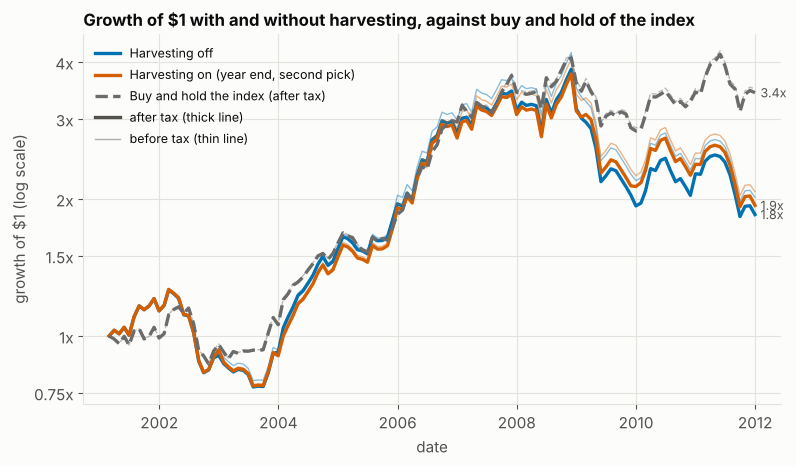

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
tp.after_tax_curves({"Harvesting off": off, "Harvesting on (year end, second pick)": on}, baseline=idx, ax=ax,
                    title="Growth of $1 with and without harvesting, against buy and hold of the index")
ax.set_ylabel("growth of $1 (log scale)"); ax.set_xlabel("date")
plt.show()

In [9]:
md(f"""
**What the evidence says.** Harvesting raised after-tax growth from {pc(off_at_cagr)} to {pc(on_at_cagr)} a year and the value of $100,000 from {usd(at_off)} to {usd(at_on)}. Of the {usd(gain_at)}, {usd(gain_tax)} came from tax and {usd(gain_pre)} came from the before-tax return, so about {pc(gain_pre / gain_at, 0)} of the measured gain was the second picks doing better than the names they replaced, which is not a property of the technique. Neither portfolio came near the base case. Buying and holding the index grew {pc(idx_at_cagr)} a year after tax and turned $100,000 into {usd(at_idx)}, {usd(gap_on)} more than the harvesting portfolio, because the screen itself trailed the index by {pts(off_at_cagr - idx_at_cagr)} points a year after tax before any harvesting.
""")


**What the evidence says.** Harvesting raised after-tax growth from 5.83% to 6.29% a year and the value of \$100,000 from \$184,817 to \$193,582. Of the \$8,765, \$2,982 came from tax and \$5,782 came from the before-tax return, so about 66% of the measured gain was the second picks doing better than the names they replaced, which is not a property of the technique. Neither portfolio came near the base case. Buying and holding the index grew 12.03% a year after tax and turned \$100,000 into \$342,399, \$148,817 more than the harvesting portfolio, because the screen itself trailed the index by -6.20 points a year after tax before any harvesting.


### 2.2 Where the tax went

The second question is how the saving arose, year by year. A harvested loss is set against gains in the year it is sold, carried back against tax already paid, or carried forward, so the saving can arrive in a different year from the sale. The charts below show the tax paid each year, the stock of unused losses carried forward, and the timeline of the sales, each against buy and hold of the index.

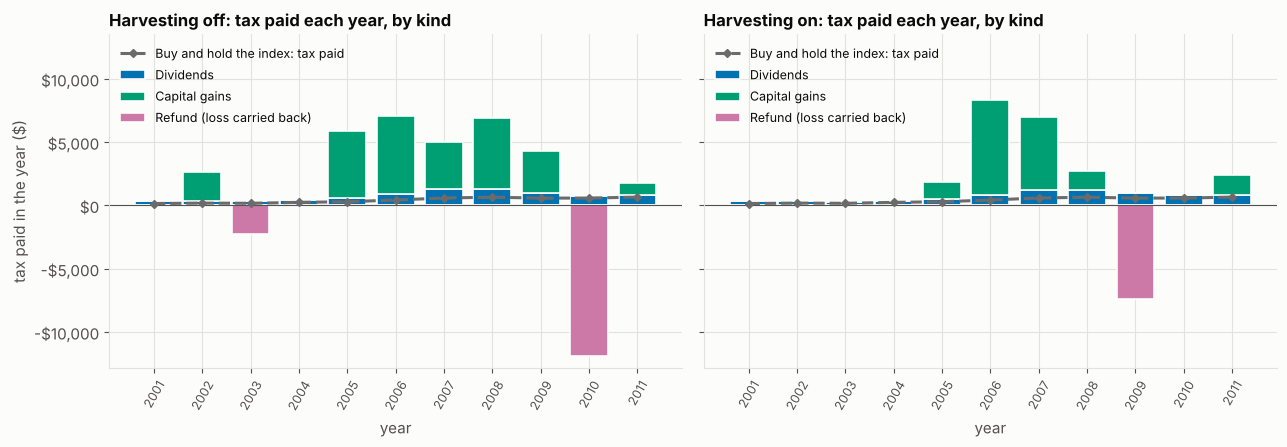

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, res, name in zip(axs, (off, on), ("Harvesting off", "Harvesting on")):
    tp.tax_paid_stack(res, ax=ax, baseline=idx, baseline_label="Buy and hold the index: tax paid",
                      title=f"{name}: tax paid each year, by kind")
    ax.set_xlabel("year"); ax.yaxis.set_major_formatter(lambda v, _: usd(v))
top = max(ax.get_ylim()[1] for ax in axs)
for ax in axs:
    ax.set_ylim(top=top * 1.45)
axs[1].set_ylabel("")
fig.tight_layout(); plt.show()

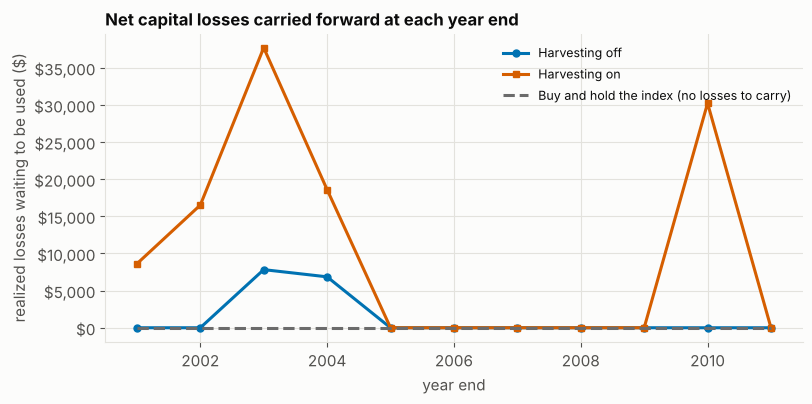

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for res, label, col, mk in ((off, "Harvesting off", OFF_COL, "o"), (on, "Harvesting on", ON_COL, "s")):
    s = res.tax["loss_carry_out"] * 1.0
    ax.plot(s.index, s.values, color=col, lw=2.2, marker=mk, ms=5, label=label)
s = idx.tax["loss_carry_out"] * 1.0
ax.plot(s.index, s.values, color=tp.INDEX_COL, ls="--", lw=2.2, label="Buy and hold the index (no losses to carry)", zorder=4)
ax.yaxis.set_major_formatter(lambda v, _: usd(v))
ax.set_ylabel("realized losses waiting to be used ($)"); ax.set_xlabel("year end")
ax.set_title("Net capital losses carried forward at each year end", loc="left", fontsize=12, fontweight="bold")
ax.legend(loc="upper right", fontsize=9); plt.show()

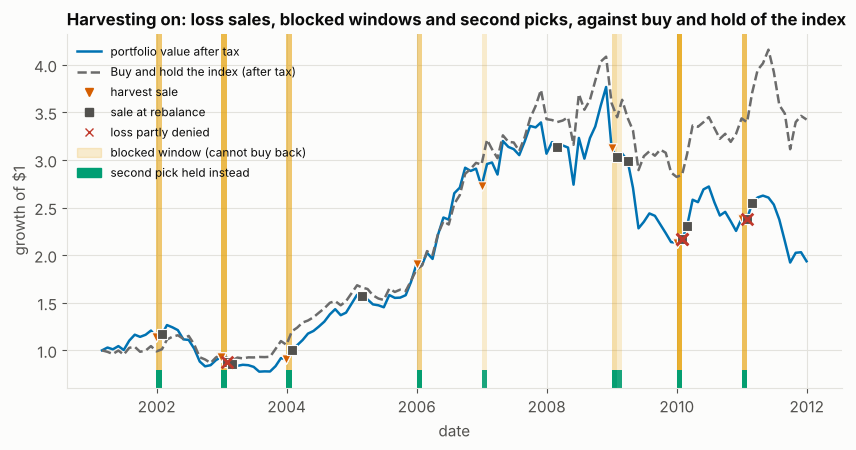

34 harvest sales, 4 with a denied loss, 34 with a second pick held for the window


In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6))
tp.harvest_timeline(on, ax=ax, baseline=idx, after_tax=True,
                    title="Harvesting on: loss sales, blocked windows and second picks, against buy and hold of the index")
ax.set_xlabel("date"); plt.show()
print(f"{n_h} harvest sales, {n_denied} with a denied loss, {on.harvest['replacement_name'].notna().sum()} with a second pick held for the window")

In [13]:
md(f"""
**What the evidence says.** The saving of {usd(tax_off - tax_on)} was the net of much larger swings between years. Harvesting on paid less tax than harvesting off in {n_less} of {n_years} years, by as much as {usd(tax_diff[y_best])} in {y_best}, and paid more in {n_more}, by as much as {usd(-tax_diff[y_worst])} in {y_worst}, because the refund that harvesting off received in {y_worst} had no counterpart. A large part of the effect was therefore a change in when tax was paid. The stock of unused losses reached {usd(on.tax['loss_carry_out'].max())} in {int(on.tax['loss_carry_out'].idxmax())} with harvesting on, against {usd(off.tax['loss_carry_out'].max())} at its highest with harvesting off, so harvesting stored far more losses for later years. The index paid {usd(tax_idx)} over the whole run, all of it on dividends, because buy and hold realizes no gains and no losses. The timeline shows {n_h} harvest sales and {n_sales - n_h} sales at the screen's own rebalance, and {n_denied} sales in which the rule denied part of the loss.
""")


**What the evidence says.** The saving of \$3,249 was the net of much larger swings between years. Harvesting on paid less tax than harvesting off in 5 of 11 years, by as much as \$10,693 in 2009, and paid more in 5, by as much as \$11,897 in 2010, because the refund that harvesting off received in 2010 had no counterpart. A large part of the effect was therefore a change in when tax was paid. The stock of unused losses reached \$37,703 in 2003 with harvesting on, against \$7,825 at its highest with harvesting off, so harvesting stored far more losses for later years. The index paid \$4,568 over the whole run, all of it on dividends, because buy and hold realizes no gains and no losses. The timeline shows 34 harvest sales and 29 sales at the screen's own rebalance, and 4 sales in which the rule denied part of the loss.


### 2.3 How the gain depends on the settings

The third question is whether the gain was a property of the 10% year-end rule or of the one setting chosen. The stage leaves two choices open: how far a name must fall before it is sold (5%, 10% or 20%), and when it may be sold (only at the year end, only at the screen's own rebalance, or at both). The notebook ran all nine combinations. The first chart shows each run's after-tax value against the two base cases, buy and hold the index and harvesting off, and the second enlarges the differences from harvesting off.

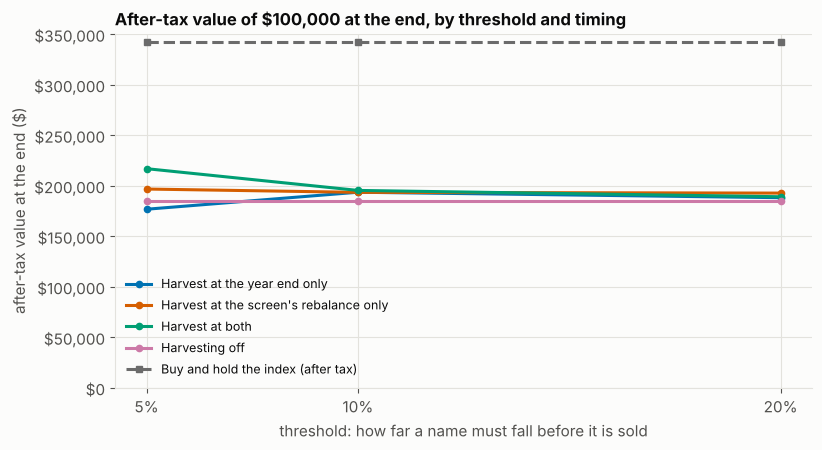

In [14]:
wide = sens.pivot(index="threshold", columns="when", values="final")[WHEN].reset_index()
wide["Harvesting off"] = at_off
wide[BH_INDEX] = at_idx
fig, ax = plt.subplots(figsize=(9, 4.6))
tp.sensitivity_lines(wide, "threshold", {"year_end": "Harvest at the year end only", "rebalance": "Harvest at the screen's rebalance only",
                                          "both": "Harvest at both", "Harvesting off": "Harvesting off", BH_INDEX: BH_INDEX},
                     ax=ax, baseline=(BH_INDEX,), xlabel="threshold: how far a name must fall before it is sold",
                     title="After-tax value of $100,000 at the end, by threshold and timing")
ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.set_xticks(THR, [f"{t:.0%}" for t in THR])
ax.set_ylabel("after-tax value at the end ($)"); ax.set_ylim(bottom=0)
plt.show()

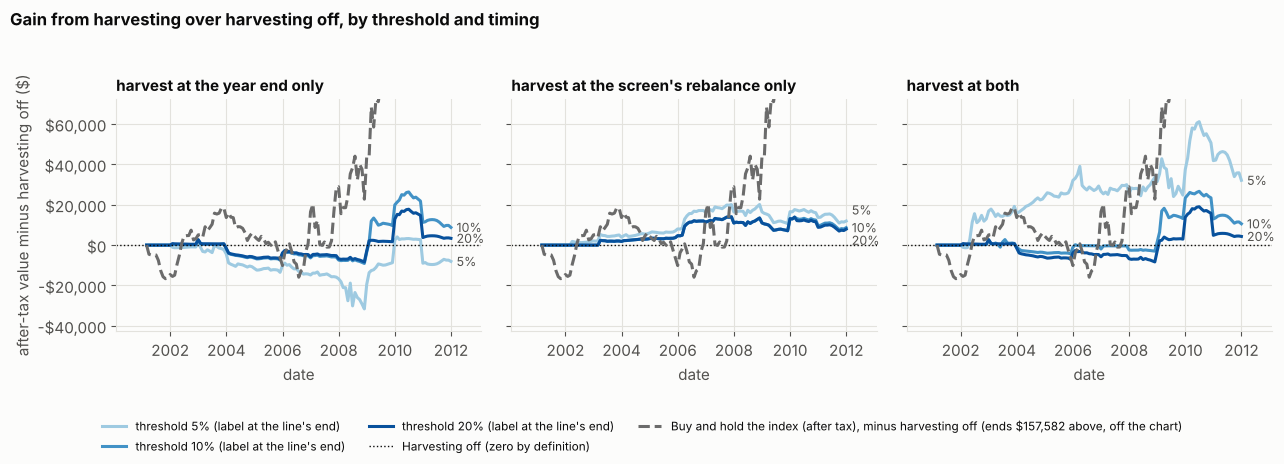

when,year_end,rebalance,both
Buy and hold the index (after tax),"$157,582","$157,582","$157,582"
Harvesting off,$0,$0,$0
Harvest when down 5%,"-$8,077","$11,921","$32,088"
Harvest when down 10%,"$8,765","$8,647","$10,561"
Harvest when down 20%,"$3,361","$7,902","$4,289"


In [15]:
shades = {0.05: "#9ecae1", 0.10: "#4292c6", 0.20: "#08519c"}
lo, hi = min(c.min() for c in curves.values()), max(c.max() for c in curves.values())
pad = 0.12 * (hi - lo)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
titles = {"year_end": "harvest at the year end only", "rebalance": "harvest at the screen's rebalance only", "both": "harvest at both"}
for ax, when in zip(axs, WHEN):
    for th in THR:
        s = curves[when, th]
        ax.plot(s.index, s.values, color=shades[th], lw=2.2)
        ax.annotate(f"{th:.0%}", (s.index[-1], s.values[-1]), xytext=(4, {0.05: 8, 0.10: 0, 0.20: -8}[th] if when == "rebalance" else 0),
                    textcoords="offset points", fontsize=9, color=INK2, va="center")
    ax.plot(idx.after_tax_curve.index, (idx.after_tax_curve - off.after_tax_curve).values * CAP, color=tp.INDEX_COL, ls="--", lw=2.2, zorder=4)
    ax.axhline(0, color=INK, lw=1.0, ls=":")
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_title(titles[when], loc="left", fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.margins(x=0.1); ax.set_xlabel("date")
axs[0].set_ylabel("after-tax value minus harvesting off ($)")
handles = [Line2D([], [], color=shades[t], lw=2.2, label=f"threshold {t:.0%} (label at the line's end)") for t in THR]
handles += [Line2D([], [], color=INK, lw=1.0, ls=":", label="Harvesting off (zero by definition)"),
            Line2D([], [], color=tp.INDEX_COL, ls="--", lw=2.2, label=BH_INDEX + f", minus harvesting off (ends {usd(idx_gain_vs_off)} above, off the chart)")]
fig.suptitle("Gain from harvesting over harvesting off, by threshold and timing", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8.5, frameon=False)
fig.tight_layout(rect=(0, 0.13, 1, 0.95)); plt.show()
gain_tab = sens.pivot(index="threshold", columns="when", values="gain")[WHEN]
gain_tab.index = [f"Harvest when down {t:.0%}" for t in gain_tab.index]
gain_tab.loc["Harvesting off"] = 0.0
gain_tab.loc[BH_INDEX] = idx_gain_vs_off
display(gain_tab.loc[[BH_INDEX, "Harvesting off", *[i for i in gain_tab.index if i.startswith("Harvest when")]]]
        .style.format(usd).set_caption("After-tax value at the end minus harvesting off, $100,000 start"))

In [16]:
md(f"""
**What the evidence says.** The gain over harvesting off was positive in {n_pos} of the nine runs and negative in {n_neg}. It ranged from {usd(worst['gain'])} (threshold {worst['threshold']:.0%}, sales {WHEN_NAME[worst['when']]}) to {usd(best['gain'])} (threshold {best['threshold']:.0%}, sales {WHEN_NAME[best['when']]}), and the 10% year-end run of {usd(gain_at)} sat {'above' if gain_at > sens['gain'].median() else 'below'} the median of {usd(sens['gain'].median())}. A threshold of 5% made {int(hv_by_thr.loc[0.05, 'min'])} to {int(hv_by_thr.loc[0.05, 'max'])} harvest sales and a threshold of 20% made {int(hv_by_thr.loc[0.20, 'min'])} to {int(hv_by_thr.loc[0.20, 'max'])}, so the lower threshold harvested more often. It also produced both the best and the worst result, which shows that harvesting more often did not reliably gain more: each sale gave up a name that might have recovered, and each swap into a second pick and back exposed the result to how the second pick performed. The spread between the best and the worst run was {usd(best['gain'] - worst['gain'])}, {(best['gain'] - worst['gain']) / gain_at:.1f} times the gain of the 10% year-end run, so the choice of setting mattered more than the technique. All nine runs together stayed far below the base case: the best harvesting run ended {usd(at_idx - sens['final'].max())} below buy and hold of the index. The history is one synthetic draw, so the direction and the order of magnitude carry the information, not the dollars.
""")


**What the evidence says.** The gain over harvesting off was positive in 8 of the nine runs and negative in 1. It ranged from -\$8,077 (threshold 5%, sales at the year end only) to \$32,088 (threshold 5%, sales at both), and the 10% year-end run of \$8,765 sat above the median of \$8,647. A threshold of 5% made 14 to 73 harvest sales and a threshold of 20% made 9 to 30, so the lower threshold harvested more often. It also produced both the best and the worst result, which shows that harvesting more often did not reliably gain more: each sale gave up a name that might have recovered, and each swap into a second pick and back exposed the result to how the second pick performed. The spread between the best and the worst run was \$40,166, 4.6 times the gain of the 10% year-end run, so the choice of setting mattered more than the technique. All nine runs together stayed far below the base case: the best harvesting run ended \$125,493 below buy and hold of the index. The history is one synthetic draw, so the direction and the order of magnitude carry the information, not the dollars.


## 3. Carry-back: a loss that refunds tax already paid

Section 2 reported refunds in the tax tables without explaining them. This section asks how a loss turns into a refund and when it cannot. Canada lets a net capital loss be applied to the taxable gains of the **three previous years**, most recent first, and the tax paid on them is refunded. Whatever remains carries forward and offsets only future gains.

Two hand-built cases use a flat 20% rate. In the first, gains were taxed in three years and a loss followed in the fourth. In the second, the loss was large enough to run out of years. These cases are bare tax events with no price path, so they have no index to hold. The base case in the first two charts is therefore the never-sell holder, who realizes no loss and receives no refund, drawn as the grey dashed zero line. The third chart returns to the section 2 run and compares the cumulative tax paid with harvesting off, harvesting on and buy and hold of the index.

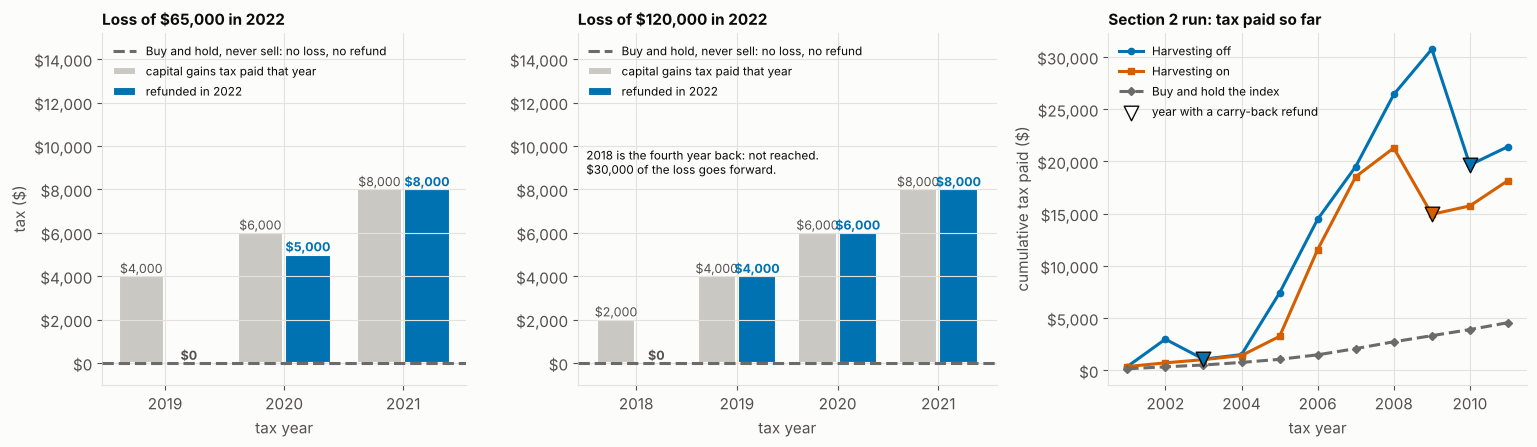

,"case 1 ($65,000 loss)","case 2 ($120,000 loss)","buy and hold, never sell"
realized_losses,"-$65,000","-$120,000",$0
carried_back,"$65,000","$90,000",$0
refund,"$13,000","$18,000",$0
loss_carry_out,$0,"$30,000",$0


carry-back refund: case 1 $13,000, case 2 $18,000; carried forward in case 2: $30,000


In [17]:
def carry_chart(t, ax, title, years, loss_year=2022):
    by = t.attrs["year_tax"][loss_year].breakdown["refund_by_year"]
    x = np.arange(len(years)); paid = [t.loc[y, "tax_capital_gains"] for y in years]; back = [by.get(y, 0.0) for y in years]
    ax.axhline(0, color=tp.INDEX_COL, ls="--", lw=2.2, label="Buy and hold, never sell: no loss, no refund", zorder=4)
    ax.bar(x - 0.2, paid, 0.38, color="#c9c8c2", label="capital gains tax paid that year", edgecolor=SURFACE, lw=1.5)
    ax.bar(x + 0.2, back, 0.38, color=BLUE, label=f"refunded in {loss_year}", edgecolor=SURFACE, lw=1.5)
    for xi, p, b in zip(x, paid, back):
        ax.text(xi - 0.2, p + 150, usd(p), ha="center", fontsize=9, color=INK2)
        ax.text(xi + 0.2, b + 150, usd(b), ha="center", fontsize=9, color=BLUE if b else INK2, fontweight="bold")
    ax.set_xticks(x, [str(y) for y in years]); ax.yaxis.set_major_formatter(lambda v, _: usd(v))
    ax.set_ylim(-1_000, max(paid) * 1.9)
    ax.set_xlabel("tax year"); ax.set_title(title, loc="left", fontsize=11, fontweight="bold"); ax.legend(loc="upper left", fontsize=8.5)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.6), gridspec_kw=dict(width_ratios=[1, 1.15, 1.15]))
carry_chart(case1, axs[0], "Loss of $65,000 in 2022", [2019, 2020, 2021])
carry_chart(case2, axs[1], "Loss of $120,000 in 2022", [2018, 2019, 2020, 2021])
axs[1].text(0.02, 0.60, "2018 is the fourth year back: not reached.\n$30,000 of the loss goes forward.", transform=axs[1].transAxes, ha="left", fontsize=8.5, color=INK)
axs[0].set_ylabel("tax ($)")
ax = axs[2]
for res, label, col, mk in ((off, "Harvesting off", OFF_COL, "o"), (on, "Harvesting on", ON_COL, "s"), (idx, "Buy and hold the index", tp.INDEX_COL, "D")):
    ax.plot(res.tax.index, res.tax["cum_tax_paid"], color=col, lw=2.2, marker=mk, ms=4.5, ls="--" if res is idx else "-", label=label, zorder=4 if res is idx else 3)
for res, col, yrs in ((off, OFF_COL, refund_years_off), (on, ON_COL, refund_years_on)):
    ax.scatter(yrs, [res.tax.loc[y, "cum_tax_paid"] for y in yrs], marker="v", s=110, color=col, edgecolor=INK, zorder=6)
ax.scatter([], [], marker="v", s=110, color="white", edgecolor=INK, label="year with a carry-back refund")
ax.yaxis.set_major_formatter(lambda v, _: usd(v)); ax.set_xlabel("tax year"); ax.set_ylabel("cumulative tax paid ($)")
ax.set_title("Section 2 run: tax paid so far", loc="left", fontsize=11, fontweight="bold"); ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout(); plt.show()
show = pd.DataFrame({"case 1 ($65,000 loss)": case1.loc[2022, ["realized_losses", "carried_back", "refund", "loss_carry_out"]],
                     "case 2 ($120,000 loss)": case2.loc[2022, ["realized_losses", "carried_back", "refund", "loss_carry_out"]]})
show["buy and hold, never sell"] = 0.0
display(show.style.format(usd))
print(f"carry-back refund: case 1 {usd(case1.loc[2022, 'refund'])}, case 2 {usd(case2.loc[2022, 'refund'])};"
      f" carried forward in case 2: {usd(case2.loc[2022, 'loss_carry_out'])}")

In [18]:
md(f"""
The loss year's `tax_paid` becomes a credit (a negative number), which is the refund received on filing for the loss year. A real return asks for it with form T1A, and the model assumes it was filed. A forward balance is not carried back later.

**What the evidence says.** The refund was the 20% rate times the part of the loss that found tax already paid. In case 1 the {usd(-case1.loc[2022, 'realized_losses'])} loss was applied to 2021 and then 2020 and refunded {usd(case1.loc[2022, 'refund'])}. In case 2 only the three years 2019 to 2021 were reached, so {usd(case2.loc[2022, 'carried_back'])} of the {usd(-case2.loc[2022, 'realized_losses'])} loss was refunded {usd(case2.loc[2022, 'refund'])} and {usd(case2.loc[2022, 'loss_carry_out'])} went forward to wait for future gains. In the section 2 run the carry-back mattered less than the sales that caused it. With harvesting on there was one refund, {usd(refund_on)} in {refund_years_on[0]}, and with harvesting off there were {len(refund_years_off)}, together {usd(refund_off)}, so harvesting did not raise the refunds. It used its losses against gains in the year they arose and needed the carry-back less: in {same_y} it realized {usd(-on.tax.loc[same_y, 'realized_losses'])} of losses against {usd(on.tax.loc[same_y, 'realized_gains'])} of gains and paid {usd(on.tax.loc[same_y, 'tax_paid'])} of tax, where harvesting off paid {usd(off.tax.loc[same_y, 'tax_paid'])}. Buy and hold of the index never had a refund to claim, because it never had a loss to carry.
""")


The loss year's `tax_paid` becomes a credit (a negative number), which is the refund received on filing for the loss year. A real return asks for it with form T1A, and the model assumes it was filed. A forward balance is not carried back later.

**What the evidence says.** The refund was the 20% rate times the part of the loss that found tax already paid. In case 1 the \$65,000 loss was applied to 2021 and then 2020 and refunded \$13,000. In case 2 only the three years 2019 to 2021 were reached, so \$90,000 of the \$120,000 loss was refunded \$18,000 and \$30,000 went forward to wait for future gains. In the section 2 run the carry-back mattered less than the sales that caused it. With harvesting on there was one refund, \$7,372 in 2009, and with harvesting off there were 2, together \$14,100, so harvesting did not raise the refunds. It used its losses against gains in the year they arose and needed the carry-back less: in 2008 it realized \$26,013 of losses against \$36,142 of gains and paid \$2,751 of tax, where harvesting off paid \$6,902. Buy and hold of the index never had a refund to claim, because it never had a loss to carry.


## 4. Exits: the sale that a risk signal makes

Sections 1 to 3 treated the sale as a choice made for tax. This section asks what happens when a risk signal forces the sale. It follows from the others because the rule does not care why the account sold: an exit policy parks the portfolio in cash while a risk flag is on, which sells everything, including a name sitting on a loss. That sale is a loss like any other, so the stage records it (`source` "exit") and blocks the name.

The flag went on at **S = 1 September 2020**, when A was down 20% from its purchase price of 1.0. A was back to 1.0 on 20 September and to 1.1 on 5 October. Three ways the flag could clear were run. In the first, the flag cleared at S + 10 days and the second pick took the money: A was blocked until S + 30, B was held, and A came back at S + 31. In the second, the flag cleared at S + 31 days, just after the window, and A was bought straight back. In the third, the flag cleared at S + 10 days and the rule was set to allow denial, so A was bought back at once and the loss was denied.

The base case is the same account that holds A and never sells, which means no exit signal and no harvesting. It is the right comparison because it shows what the exit and the window cost in forgone gains, which the table of losses alone cannot show.

In [19]:
display(t4)

,sale recorded as,loss,bought instead,A held again on,denied,loss realized in 2020,wealth on 6 Oct
variant,,,,,,,
"Buy and hold A (no exit, never sell)",-,$0,-,-,$0,$0,"$110,000"
"Back in at S+10, second pick",exit,"$20,000",B,2020-10-02,$0,"$20,000","$88,000"
"Back in at S+31, second pick",exit,"$20,000",A (the same name),2020-10-02,$0,"$20,000","$88,000"
"Back in at S+10, allow denial",exit,"$20,000",A (the same name),2020-09-11,"$20,000",$0,"$110,000"


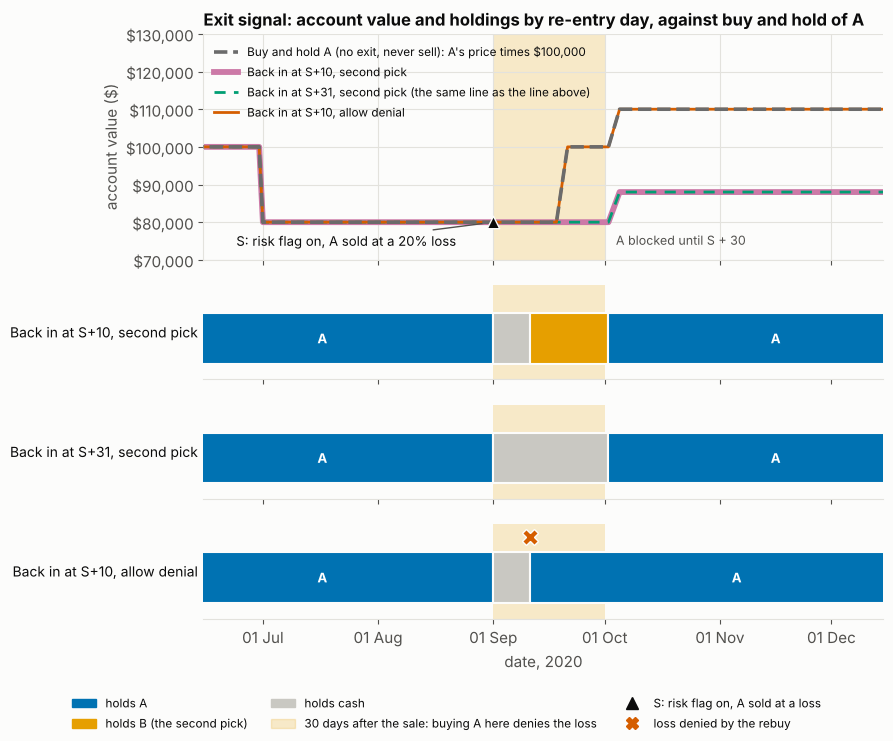

In [20]:
fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 7.4), gridspec_kw=dict(height_ratios=[2.4, 1, 1, 1], hspace=0.2))
win = (S, S + pd.Timedelta(days=30)); ax = axs[0]
ax.plot(a_exit.index, a_exit.values * CAP, color=tp.INDEX_COL, ls="--", lw=2.6, label=BH_A4 + ": A\'s price times $100,000", zorder=5)
for k, r in res4.items():
    ax.plot(r.curve.index, r.curve.values * CAP, color=EXIT_COL[k], lw=4.2 if k.startswith("Back in at S+10, second") else 2.0,
            ls=(0, (4, 3)) if k.startswith("Back in at S+31") else "-", label=k + (" (the same line as the line above)" if k.startswith("Back in at S+31") else ""))
ax.scatter([S], [a_exit.loc[S] * CAP], marker="^", s=80, color=INK, zorder=6, edgecolor=SURFACE)
ax.annotate("S: risk flag on, A sold at a 20% loss", (S, a_exit.loc[S] * CAP), xytext=(-185, -17), textcoords="offset points", fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2))
ax.axvspan(mdates_num(win[0]), mdates_num(win[1]), color=ORANGE, alpha=0.20, lw=0, zorder=0)
ax.text(S + pd.Timedelta(days=33), 74_000, "A blocked until S + 30", fontsize=9, color=INK2)
ax.set_ylabel("account value ($)"); ax.set_ylim(70_000, 130_000); ax.yaxis.set_major_formatter(lambda x, _: usd(x))
ax.legend(loc="upper left", fontsize=8.5)
ax.set_title("Exit signal: account value and holdings by re-entry day, against buy and hold of A", loc="left", fontsize=12, fontweight="bold")
for ax_, (name, (b, _)), r in zip(axs[1:], EXITS.items(), res4.values()):
    h = r.harvest.iloc[0]
    draw_held(ax_, held_segments(r, "A", end=pd.Timestamp("2020-12-31"), reentry=b, start=pd.Timestamp("2020-06-01")), name, window=win,
              denied_at=b if h["denied"] > 0 else None)
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axs[-1].set_xlim(pd.Timestamp("2020-06-15"), pd.Timestamp("2020-12-15")); axs[-1].set_xlabel("date, 2020")
strip_legend(fig, "S: risk flag on, A sold at a loss", "^", INK)
fig.subplots_adjust(left=0.22, bottom=0.16, top=0.95)
plt.show()

In [21]:
rows4_loss = res4["Back in at S+10, second pick"].harvest.iloc[0]["loss"] * CAP
rows4_denied = res4["Back in at S+10, allow denial"].harvest.iloc[0]["denied"] * CAP

In [22]:
md(f"""
**What the evidence says.** An exit sale was treated as a harvest sale, and in this made-up path the window was expensive. The exit realized a {usd(rows4_loss)} loss in all three variants, but with the second pick the account bought A back on 2 October at 1.0 after A had already risen from 0.8, so on 6 October it was worth {usd(w4['Back in at S+10, second pick'])} against {usd(bh4)} for buy and hold of A. The {usd(bh4 - w4['Back in at S+10, second pick'])} difference was the rebound the account missed, set against a tax value of {usd(rows4_loss * FLAT_RATE)} at 20%. Clearing the flag at S + 31 changed nothing, because both second-pick variants bought A back on the same day. Allow denial recovered the rebound, with {usd(w4['Back in at S+10, allow denial'])} on 6 October, the same as buy and hold, but forfeited the loss: {usd(rows4_denied)} was denied. On this path the rule cost more than the loss was worth. The path was built to show the mechanics, and on a path where A kept falling the comparison would reverse.
""")


**What the evidence says.** An exit sale was treated as a harvest sale, and in this made-up path the window was expensive. The exit realized a \$20,000 loss in all three variants, but with the second pick the account bought A back on 2 October at 1.0 after A had already risen from 0.8, so on 6 October it was worth \$88,000 against \$110,000 for buy and hold of A. The \$22,000 difference was the rebound the account missed, set against a tax value of \$4,000 at 20%. Clearing the flag at S + 31 changed nothing, because both second-pick variants bought A back on the same day. Allow denial recovered the rebound, with \$110,000 on 6 October, the same as buy and hold, but forfeited the loss: \$20,000 was denied. On this path the rule cost more than the loss was worth. The path was built to show the mechanics, and on a path where A kept falling the comparison would reverse.


## 5. Reading guide: what the model leaves out

The sections above used a simplified model, so this section asks how far their numbers can be trusted and which omissions matter. The model sees one taxable account and treats the rule in a cautious, simplified way.

* **Spouse and affiliated accounts.** CRA also denies the loss if your spouse, your RRSP or TFSA, or a corporation you control buys the same name in the window. The model sees one taxable account only.
* **Identical property.** Swapping one ETF for another that tracks the same index may or may not count as identical for CRA. The model knows only names, and a second pick is a different company.
* **Settlement dates.** The model uses trade dates, and the real rule uses settlement dates, which fall two business days later in the market of the day.
* **"Still held at the end of the window".** The rule bites only if the rebought shares are still held at the end of the 30 days. The model treats any repurchase in the window as denying the loss, which is the cautious reading and slightly overstates the denial.
* **Small details.** The model leaves out the bid-ask spread and the real price of 30 days away from the name, since the second pick may move more or less than the original would have.
* **TFSA and RRSP.** A loss inside a registered account is worthless, so harvesting there is pointless. In a registered account **ignore the TaxDeferred/yr column**, which is computed anyway although nothing is deferred.
* **Tax law.** The flat 20% in sections 1, 3 and 4 gives clean arithmetic, and section 2 uses the library's Alberta model with brackets. Neither is tax advice.

**What the evidence says.** The first three omissions can only deny losses that the model allowed, so they would make the real saving smaller than the measured one. The fourth works the other way and is small. Taken together, the measured benefit in section 2 is more likely too high than too low, and it was already small and of uncertain sign. The notebook therefore supports a narrow conclusion: with a second pick and no rebuy inside the window, harvesting banked losses at a modest cost in trading and time away from the chosen names, and the tax it saved was small beside the choice of what to hold.

**Where to look next.** `docs/TAXES.md`, "Loss harvesting"; `tests/test_harvesting.py` (the markets above, with every number asserted); `notebooks/accounts_and_foreign.ipynb` for which account a portfolio should live in; `notebooks/tax_where_to_hold.ipynb` for the same buy-and-hold index comparison across accounts.